# ELE680 – ETTh1 Dataset Exploration

## Long-Horizon Forecasting

This notebook explores the ETTh1 dataset to understand its
structure, data quality, statistical properties, and
time-series patterns before developing forecasting models.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

print("Jupyter Notebook is working!")

Jupyter Notebook is working!


In [4]:
df = pd.read_csv("ETT-small/ETTh1.csv")
df.head()

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


In [5]:
df["date"] = pd.to_datetime(df["date"])

print("Dataset shape:", df.shape)
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Dataset shape: (17420, 8)
Start date: 2016-07-01 00:00:00
End date: 2018-06-26 19:00:00


## 1. Data Quality Checks

We check for missing values, duplicate observations,
duplicate timestamps, and irregular time intervals.

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["date"].duplicated().sum())

print("\nTime intervals:")
print(df["date"].sort_values().diff().value_counts())

Missing values:
date    0
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 0

Time intervals:
date
0 days 01:00:00    17419
Name: count, dtype: int64


## 2. Descriptive Statistics

In [7]:
df.describe()

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
count,17420,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000
mean,2017-06-28 21:30:00,7.375141,2.242242,4.300239,0.881568,3.066062,0.856932,13.324672
min,2016-07-01 00:00:00,-22.705999,-4.756000,-25.087999,-5.934000,-1.188000,-1.371000,-4.080000
25%,2016-12-29 10:45:00,5.827000,0.737000,3.296000,-0.284000,2.315000,0.670000,6.964000
50%,2017-06-28 21:30:00,8.774000,2.210000,5.970000,0.959000,2.833000,0.975000,11.396000
75%,2017-12-27 08:15:00,11.788000,3.684000,8.635000,2.203000,3.625000,1.218000,18.079000
max,2018-06-26 19:00:00,23.643999,10.114000,17.341000,7.747000,8.498000,3.046000,46.007000
std,NaN,7.067744,2.042342,6.826978,1.809293,1.164506,0.599552,8.566946


## 3. Oil Temperature Visualization

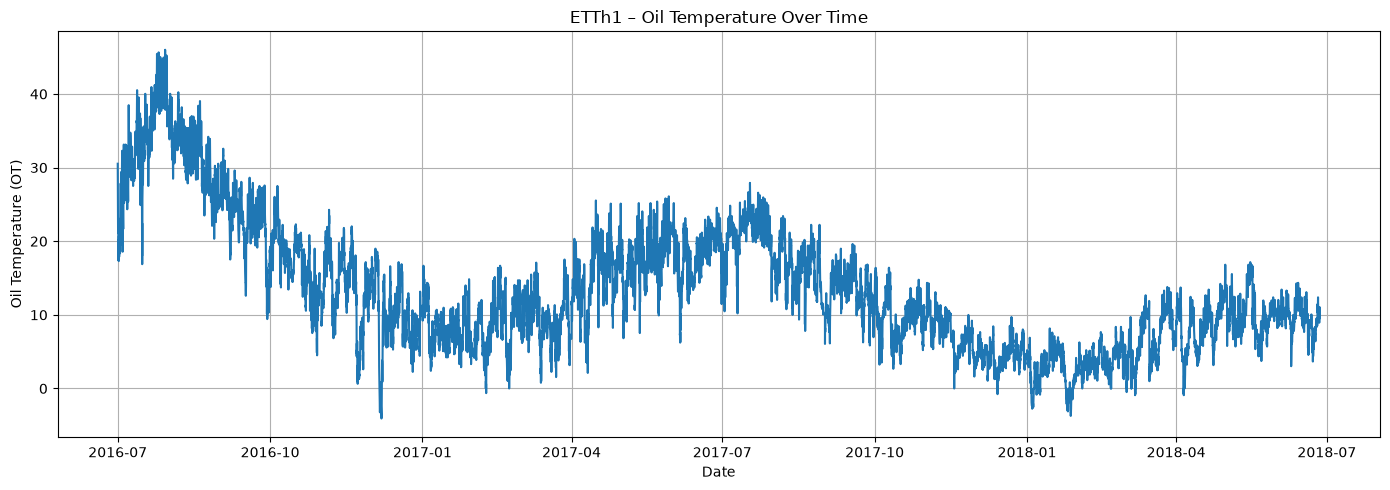

Figure saved successfully!


In [9]:

from pathlib import Path
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["OT"])

plt.title("ETTh1 – Oil Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Oil Temperature (OT)")
plt.grid(True)

# Adjust layout before saving
plt.tight_layout()

# Folder for project figures
figures_dir = Path("figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Save figure in high resolution
plt.savefig(
    figures_dir / "01_OT_Time_Series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")

### Initial Observations

- Oil temperature varies considerably throughout the dataset.
- The temperature shows longer-term changes over the two-year period.
- Higher temperatures appear during some summer periods,
  while lower temperatures appear during winter periods.
- Sudden fluctuations and possible anomalous values are visible.
- These observations suggest possible seasonal and
  non-stationary behavior, which requires further investigation.

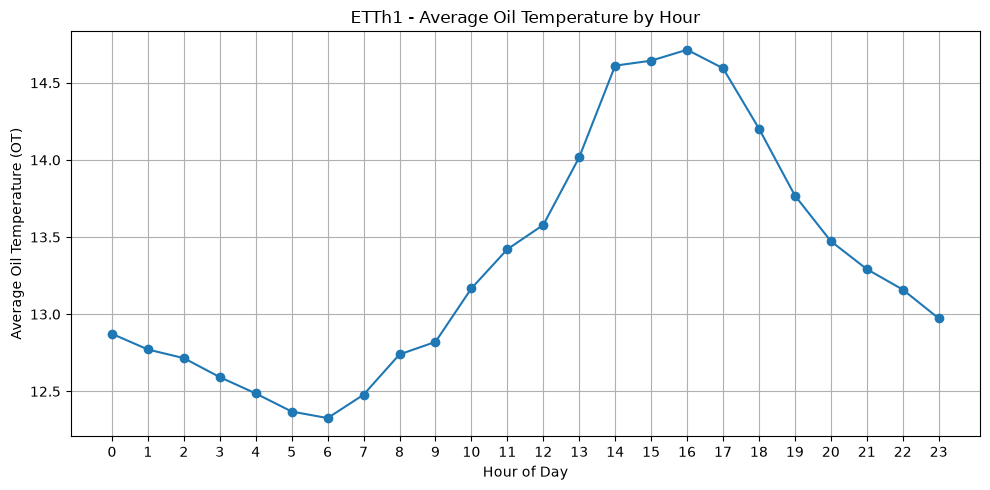

In [ ]:
# Extract the hour from each timestamp
df["hour"] = df["date"].dt.hour

# Calculate average oil temperature for each hour
hourly_avg = df.groupby("hour")["OT"].mean()

# Plot
plt.figure(figsize=(10, 5))
plt.plot(hourly_avg.index, hourly_avg.values, marker="o")

plt.title("ETTh1 - Average Oil Temperature by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Oil Temperature (OT)")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

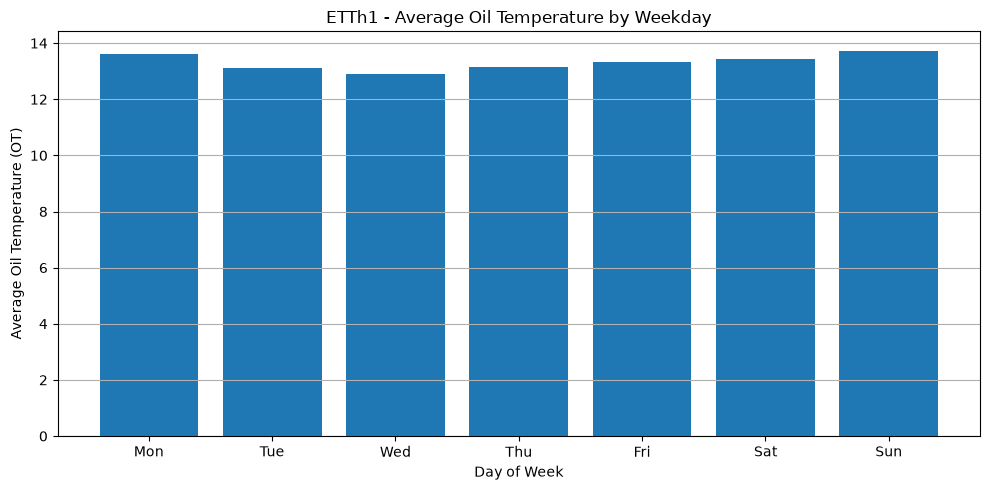

In [ ]:
# Extract weekday: Monday=0, Sunday=6
df["day_of_week"] = df["date"].dt.dayofweek

# Calculate average temperature for each weekday
weekly_avg = df.groupby("day_of_week")["OT"].mean()

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Plot
plt.figure(figsize=(10, 5))
plt.bar(days, weekly_avg.values)

plt.title("ETTh1 - Average Oil Temperature by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Oil Temperature (OT)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

### Daily and Weekly Pattern Analysis

**Daily pattern:**
- Average oil temperature varies noticeably throughout the day.
- The lowest average temperature occurs around 06:00 (approximately 12.3).
- The highest average temperature occurs around 16:00 (approximately 14.7).
- The difference is approximately 2.4 OT units.
- This suggests a daily time-of-day pattern that may be useful for forecasting.

**Weekly pattern:**
- Average oil temperatures are relatively similar across weekdays.
- Wednesday has a slightly lower average, while Sunday has a slightly higher average.
- No strong weekday effect is evident from the aggregated averages.

**Conclusion:**
The dataset exhibits a noticeable daily pattern in its average oil temperature. Further analysis is required to confirm the strength and stability of daily and weekly seasonality.

## 4. Correlation Analysis

This section investigates the linear relationships between oil
temperature (OT) and the six load-related variables in ETTh1.

In [ ]:
# Select the seven numerical variables
features = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]

# Calculate Pearson correlation matrix
corr_matrix = df[features].corr()

# Display correlations with oil temperature
corr_matrix["OT"].sort_values(ascending=False)

OT      1.000000
HULL    0.224354
MULL    0.220004
LUFL    0.118836
LULL    0.067455
HUFL    0.059916
MUFL    0.050854
Name: OT, dtype: float64

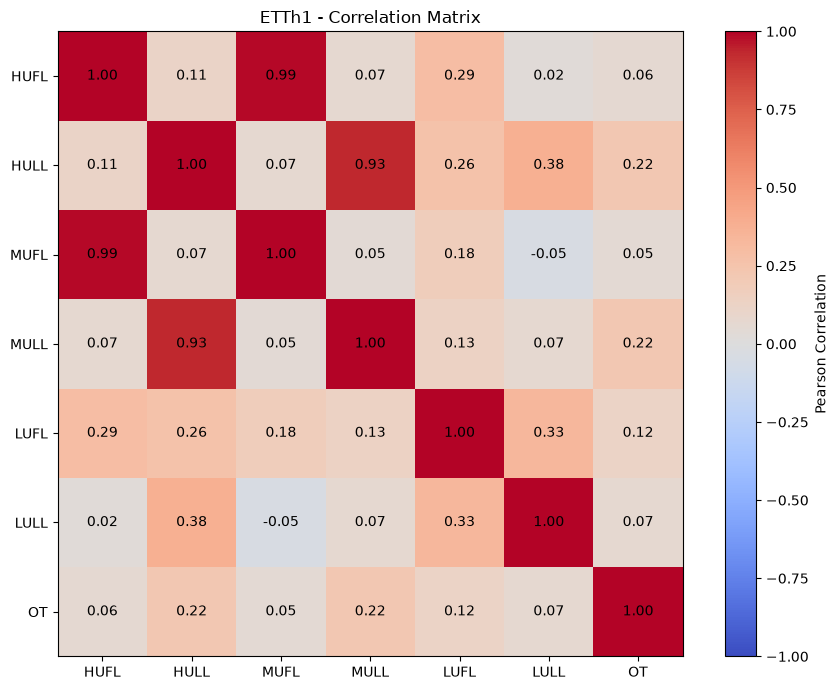

In [ ]:
import numpy as np

plt.figure(figsize=(9, 7))

plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson Correlation")

plt.xticks(range(len(features)), features)
plt.yticks(range(len(features)), features)

# Display correlation values inside each cell
for i in range(len(features)):
    for j in range(len(features)):
        plt.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.title("ETTh1 - Correlation Matrix")
plt.tight_layout()
plt.show()

### Correlation Analysis – Key Findings

- All six load variables have weak positive Pearson correlations
  with oil temperature (OT).
- HULL (0.2244) and MULL (0.2200) have the highest correlations
  with OT, although both relationships are weak.
- HUFL and MUFL are very strongly correlated (approximately 0.99).
- HULL and MULL are also strongly correlated (approximately 0.93).
- The strong relationships between some load variables suggest
  possible multicollinearity.
- Weak same-time correlations with OT do not necessarily mean
  that these variables are unhelpful for future temperature prediction.

**Conclusion:** All six load variables will initially be retained
for multivariate forecasting experiments. Their usefulness will
be evaluated through forecasting performance rather than
correlation alone.